In [1]:
import logging
logging.captureWarnings(True)

In [2]:
import numpy as np
import networkx as nx

In [3]:
from multifractal_networks.mfng import MultifractalNetworkGenerator
from multifractal_networks.mfnf import MultifractalNetworkFitter

# Generating the network

In [4]:
N = 10000
m = 3
k = 4

In [5]:
P = np.array([
    [0.28496249, 0.46450071, 0.3449749 ],
    [0.46450071, 0.00946877, 0.39117118],
    [0.34497490, 0.39117118, 0.05582052]
])
l = np.array(
    [0.08283585, 0.59124287, 0.32592127]
)

In [6]:
generator = MultifractalNetworkGenerator(P,l,k,N,num_workers=-1)

Initializing...
0.0010042190551757812


In [6]:
generator()
print(2 * generator.G.number_of_edges() / generator.G.number_of_nodes())

Initializing...
0.0010325908660888672
Preparing node pairs...
Commencing edge generation...


100%|██████████| 32/32 [00:16<00:00,  1.91it/s]


Refining network structure...
Refining 1 outlier nodes...


100%|██████████| 32/32 [00:02<00:00, 14.48it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:02<00:00, 14.30it/s]


... (7 outputs left out)

100%|██████████| 32/32 [00:02<00:00, 14.45it/s]


Refining 1 outlier nodes...


100%|██████████| 32/32 [00:02<00:00, 14.39it/s]


25.5106


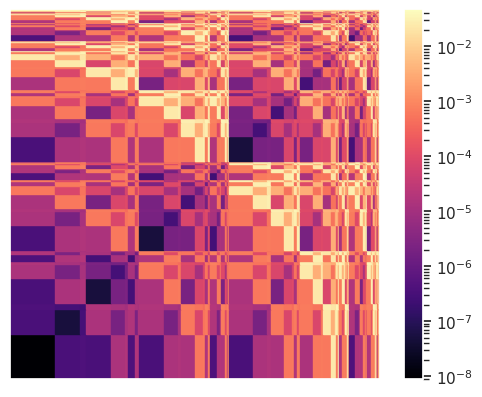

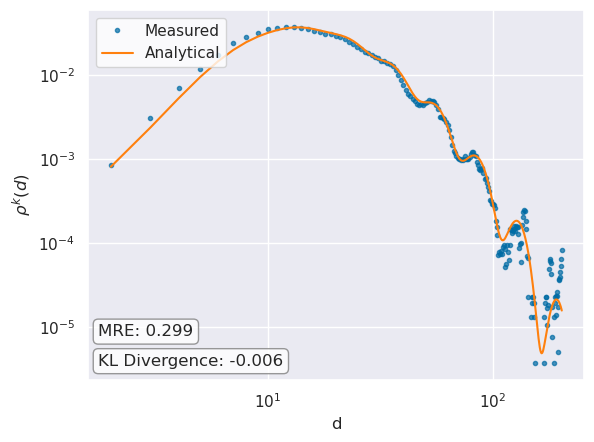

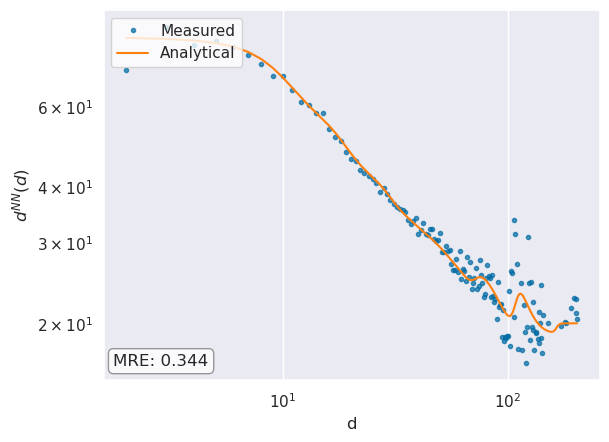

Counting motifs of size 3... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:00:10.635081
Counting motifs of size 4... grab a tea or watch a movie, this might take a while.
Motif counting finished in 0:09:35.047627


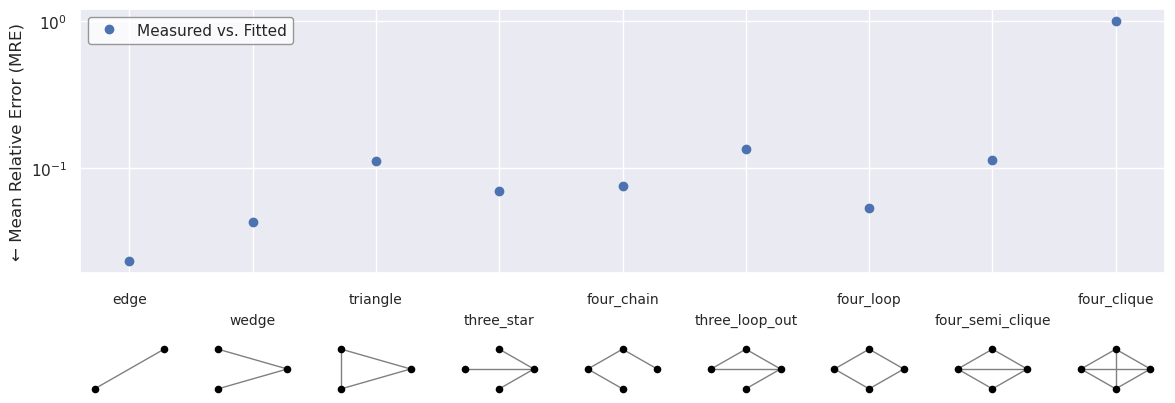

[{'name': 'edge',
  'matrix': array([[0, 1],
         [1, 0]]),
  'size': 2,
  'analytical_count': 130603.28824809701,
  'count': 127553,
  'MRE': 0.023355370978888502},
 {'name': 'wedge',
  'matrix': array([[0, 1, 1],
         [1, 0, 0],
         [1, 0, 0]]),
  'size': 3,
  'analytical_count': 5119232.830449448,
  'count': 4897477,
  'MRE': 0.043318176335022975},
 {'name': 'triangle',
  'matrix': array([[0, 1, 1],
         [1, 0, 1],
         [1, 1, 0]]),
  'size': 3,
  'analytical_count': 1332.0445895672015,
  'count': 1184,
  'MRE': 0.11114086624930707},
 {'name': 'three_star',
  'matrix': array([[0, 1, 1, 1],
         [1, 0, 0, 0],
         [1, 0, 0, 0],
         [1, 0, 0, 0]]),
  'size': 4,
  'analytical_count': 101951717.60639928,
  'count': 94819165,
  'MRE': 0.0699601024274611},
 {'name': 'four_chain',
  'matrix': array([[0, 1, 0, 0],
         [1, 0, 1, 0],
         [0, 1, 0, 1],
         [0, 0, 1, 0]]),
  'size': 4,
  'analytical_count': 161590725.46722203,
  'count': 14932070

In [9]:
#generator.plot_generated_network(
#    layout_func = nx.spring_layout,
#    largest_component_only = False,
#)

generator.network_stats(
    log_scale = True,
    filename="figures/synthetic_network_10k_plot_ground_truth.pdf",
    motif_analyzer_args = {
        'exact': True,
        'bootstrap_iters': None,
        'ci': None
    }
)

generator.motifs

In [18]:
generator.save_network('./test_networks/synthetic_network_10k.graphml')

---

# Fitting

## Load, count motifs

In [7]:
filename = './test_networks/synthetic_network_10k.graphml'
G = nx.read_graphml(filename)

In [5]:
for m_size in [2,3,5,6,7]:
    print(m_size,' k_max: ',int(np.log(len(G))/np.log(m_size**2))+1)

2  k_max:  7
3  k_max:  5
5  k_max:  3
6  k_max:  3
7  k_max:  3


In [10]:
mfnf = MultifractalNetworkFitter(G,
                                 #d_range = [1,200],
                                 motifs = [
                                     {'name': 'four_chain', 'matrix': np.array([[0, 1, 0, 0],[1, 0, 1, 0],[0, 1, 0, 1],[0, 0, 1, 0]])},
                                     {'name': 'three_loop_out', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 1, 0],[1, 1, 0, 0],[1, 0, 0, 0]])},
                                     {'name': 'four_loop', 'matrix': np.array([[0, 1, 0, 1],[1, 0, 1, 0],[0, 1, 0, 1],[1, 0, 1, 0]])},
                                     {'name': 'four_semi_clique', 'matrix': np.array([[0, 1, 1, 1],[1, 0, 0, 1],[1, 0, 0, 1],[1, 1, 1, 0]])},
                                 ],
                                 sampling_ratios = {3: None,
                                                    4: None},
                                 motif_analyzer_args={'exact': True, 'bootstrap_iters': None, 'ci': None},
                                 population_size = 100,
                                 weights = {'rho':9,
                                            'deg_nn':9,
                                            'motifs':1,
                                            'edge':9},
                                 pre_loaded_motifs = './test_networks/synthetic_network_10k_motifs.pkl'
                                )

Measuring graph properties...
Degree distribution...
Degree correlations...
Motifs...
Succesfully loaded motifs for network G from ./test_networks/synthetic_network_10k_motifs.pkl


In [22]:
mfnf.save_motifs('./test_networks/synthetic_network_10k_motifs.pkl')

## Grid Search - Find m,k,P,l together

In [29]:
mfnf.find_m_k_P_l(
    m_k_dict = [{'m': 2,   'k': [1,7]},
                {'m': 3,   'k': [1,5]},
                {'m': 5,   'k': [1,3]},
               ],
    n_trials = None,
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = False,
    grid_search = True,
    optimize_for = 'kl_energy'
)

[I 2025-01-20 08:17:36,369] A new study created in memory with name: no-name-9c6a34af-319c-47b7-aa90-cc5a3b62bd6e


Grid Search requires 6 trials...


[I 2025-01-20 08:17:59,152] Trial 0 finished with value: 3.790439082542969 and parameters: {'m': 2, 'k': 6}. Best is trial 0 with value: 3.790439082542969.
[I 2025-01-20 08:18:17,611] Trial 1 finished with value: 5.054027157728775 and parameters: {'m': 2, 'k': 3}. Best is trial 0 with value: 3.790439082542969.
[I 2025-01-20 08:18:34,058] Trial 2 finished with value: 7.1158402699618915 and parameters: {'m': 2, 'k': 2}. Best is trial 0 with value: 3.790439082542969.
[I 2025-01-20 08:18:54,446] Trial 3 finished with value: 4.140453664209796 and parameters: {'m': 2, 'k': 4}. Best is trial 0 with value: 3.790439082542969.
[I 2025-01-20 08:19:08,706] Trial 4 finished with value: 15.036211769014981 and parameters: {'m': 2, 'k': 1}. Best is trial 0 with value: 3.790439082542969.
[I 2025-01-20 08:19:28,079] Trial 5 finished with value: 3.8649579904133593 and parameters: {'m': 2, 'k': 5}. Best is trial 0 with value: 3.790439082542969.
[I 2025-01-20 08:19:28,080] A new study created in memory wit

Grid Search requires 4 trials...


[I 2025-01-20 08:20:10,104] Trial 0 finished with value: 1.801926421685914 and parameters: {'m': 3, 'k': 3}. Best is trial 0 with value: 1.801926421685914.
[I 2025-01-20 08:21:07,423] Trial 1 finished with value: 1.5913043931657895 and parameters: {'m': 3, 'k': 4}. Best is trial 1 with value: 1.5913043931657895.
[I 2025-01-20 08:21:39,977] Trial 2 finished with value: 3.0146697737497585 and parameters: {'m': 3, 'k': 2}. Best is trial 1 with value: 1.5913043931657895.
[I 2025-01-20 08:21:57,108] Trial 3 finished with value: 12.025032030181308 and parameters: {'m': 3, 'k': 1}. Best is trial 1 with value: 1.5913043931657895.
[I 2025-01-20 08:21:57,109] A new study created in memory with name: no-name-4b389c17-eb89-4993-a952-6d961a32c789


Grid Search requires 2 trials...


[I 2025-01-20 08:22:56,462] Trial 0 finished with value: 1.966291101453097 and parameters: {'m': 5, 'k': 2}. Best is trial 0 with value: 1.966291101453097.
[I 2025-01-20 08:23:24,847] Trial 1 finished with value: 12.29571006304765 and parameters: {'m': 5, 'k': 1}. Best is trial 0 with value: 1.966291101453097.


Best parameters:  {'m': 3, 'k': 4}
Best energy:  4.176879470569049
Best KL-divergence:  -0.0075990424424073446
Best KLD augumented energy: 1.5913043931657895
Best P matrix:
 [[0.01583315 0.39612174 0.44765638]
 [0.39612174 0.03289736 0.355875  ]
 [0.44765638 0.355875   0.31839969]]
Best l vector:
 [0.60174517 0.31556941 0.08268541]


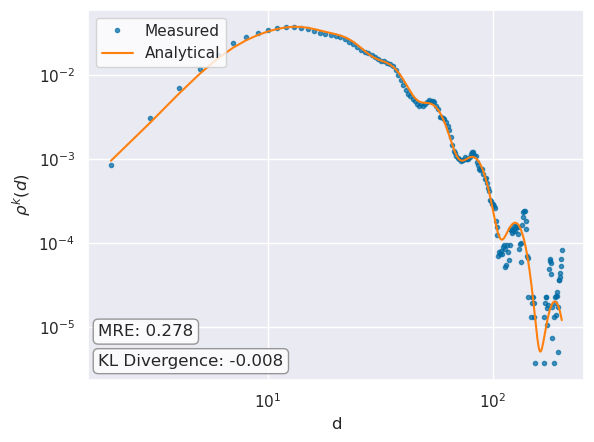

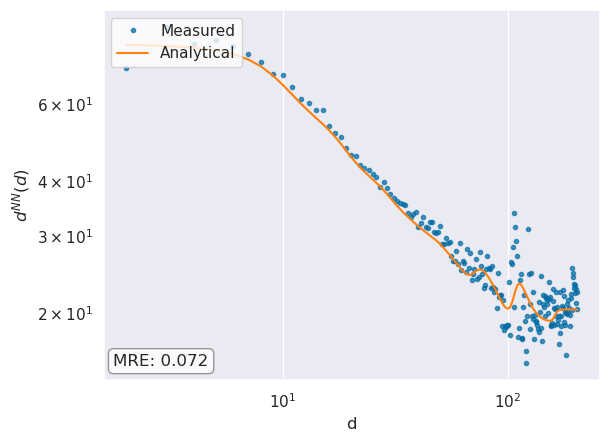

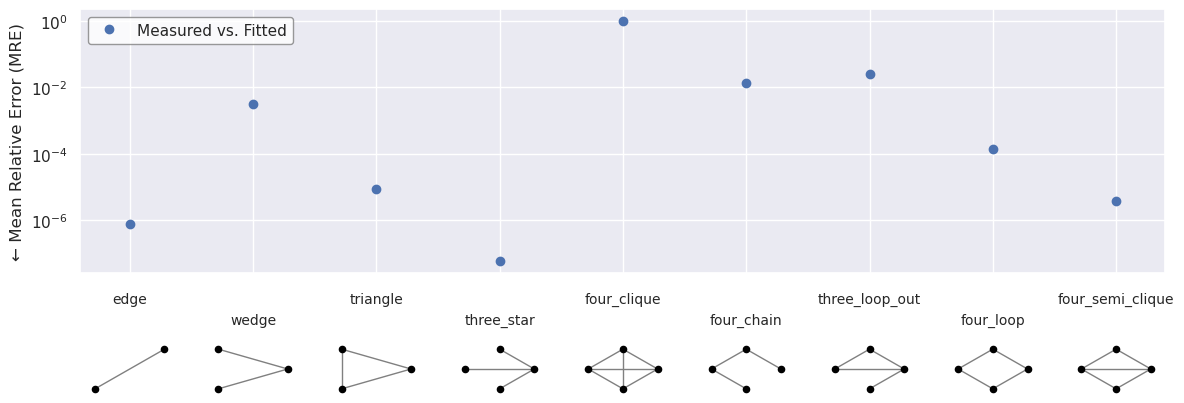

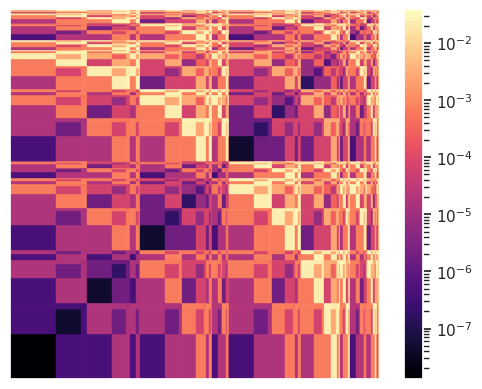

In [12]:
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_10k_plot.pdf"
)

---

## Bootstrapping stability

In [13]:
mfnf.bootstrap_P_l_stability(
    P_init = 'm x m',
    l_init = 'dirichlet',
    verbose = True,
    resample_size = mfnf.population_size * 10,
    ci = 0.95,
    medoid = 'mean'
)

Gathering statistics (300 runs)...


100%|██████████| 300/300 [4:38:15<00:00, 55.65s/it]  

Bootstrapping: Resampling 1000 times...


Bootstrapping finished in 0:00:00.641638
Energy = 4.19 (4.19, 4.22)
l = [0.59 (0.58, 0.61), 0.33 (0.31, 0.34), 0.08 (0.08, 0.08)]
P = [
[0.01 (0.00, 0.02), 0.39 (0.39, 0.40), 0.45 (0.44, 0.47)],

[0.39 (0.39, 0.40), 0.05 (0.03, 0.07), 0.36 (0.31, 0.39)],

[0.45 (0.44, 0.47), 0.36 (0.31, 0.39), 0.31 (0.27, 0.38)]
]


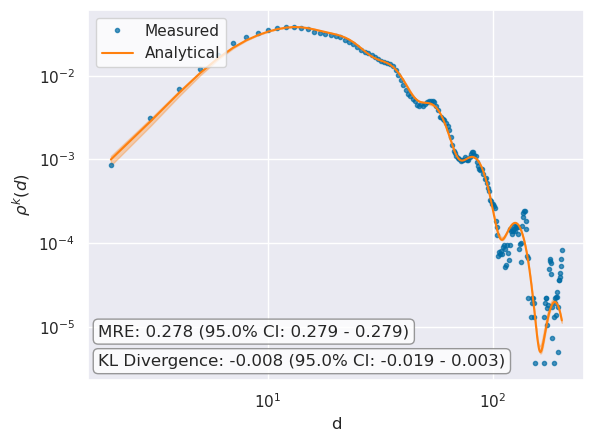

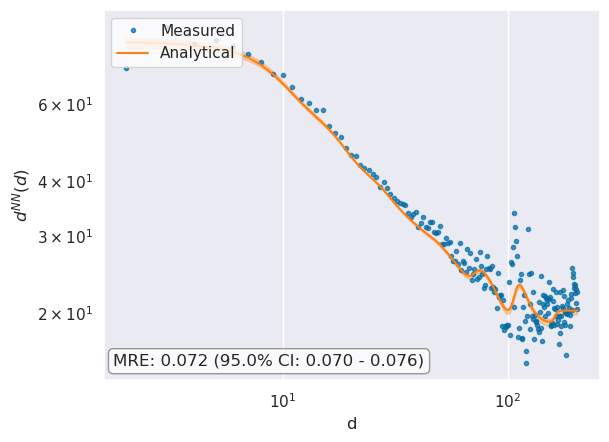

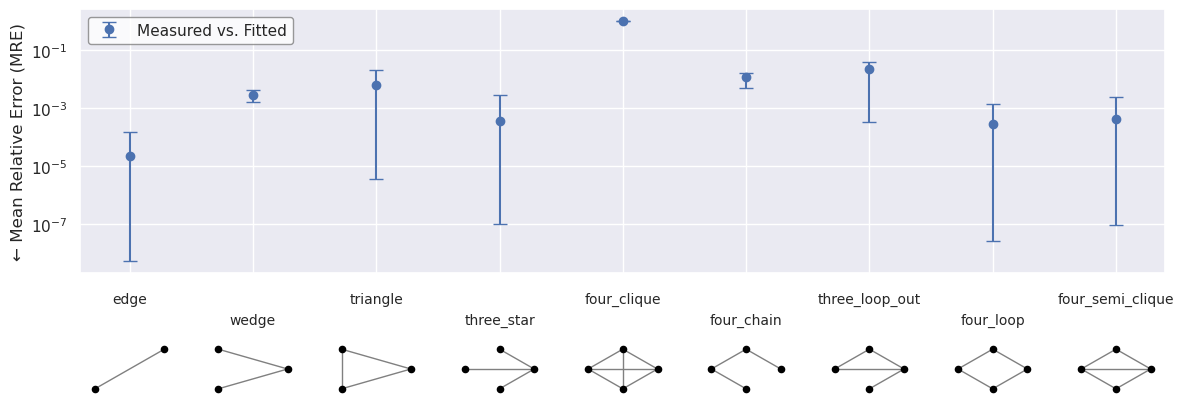

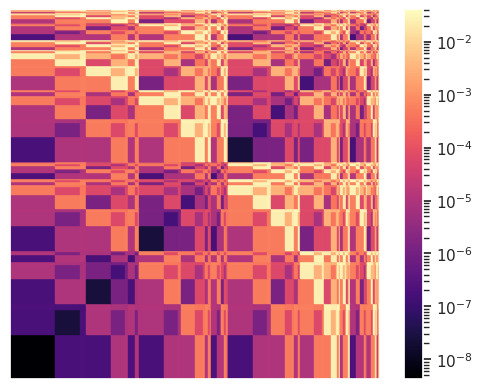

In [16]:
mfnf.plot_P_l_result(
    log_scale = True,
    grid = False,
    display_mre = True,
    display_kld = True,
    plot_cumulative_error = False,
    filename = "figures/synthetic_network_10k_plot_bootstrap.pdf"
)